In [1]:
import numpy as np
import skimage.io
import skimage.transform
import matplotlib.pyplot as plt
import constants
import tensorflow as tf
import keras
import matplotlib.pyplot as plt
import joblib
import cv2
import seaborn as sn
import pandas as pd
import matplotlib.patches as patches
import time
from sklearn.metrics import confusion_matrix
from sklearn.metrics import multilabel_confusion_matrix

In [2]:
name = 'sectie11b'
image = skimage.io.imread(f'./data/images_test/{name}.JPG')
# name = 'sectie9b'
# image = skimage.io.imread(f'./data/images_full/{name}.JPG')

In [3]:
# plt.imshow(image)

Gebruik `skimage` om een afbeelding in te lezen. Cv2 verkreurt de afbeelding zoals hieronder. Dit komt omdat cv2 BGR waarde heeft, geen RGB.

In [4]:
# test = cv2.imread('./data/images_test/sectie11.JPG')
# plt.imshow(test)

In [5]:
def img_to_512(image):
    # height = len(image)
    # width = len(image[0])
    # size_piece = 512
    labels = []
    pieces = []
    y = 0
    while(y < constants.Y_END - constants.WIDTH_PIECE): #zijkanten worden weggegooid indien te klein
        x = 0
        while(x < constants.X_END - constants.WIDTH_PIECE): #zijkanten worden weggegooid indien te klein
            x_end = x+constants.WIDTH_PIECE if x+constants.WIDTH_PIECE < constants.X_END else constants.X_END
            y_end = y+constants.WIDTH_PIECE if y+constants.WIDTH_PIECE < constants.Y_END else constants.Y_END
            #cut a piece
            img_piece = image[y:y_end,x:x_end]
            pieces.append(img_piece)
            coordinate = [x + constants.WIDTH_PIECE / 2, y + constants.WIDTH_PIECE / 2]
            labels.append(coordinate)
            x += constants.WIDTH_PIECE
        y += constants.WIDTH_PIECE
    
    return labels, pieces

In [6]:
labels, pieces = img_to_512(image)

In [7]:
# plt.imshow(image)
# plt.scatter(*zip(*labels), alpha=0.7, c='darkred', s=15)

In [8]:
def filter_512(data, labels, model):
    filtered_data = []
    filtered_label = []
    aantal = len(data)

    pred_time = 0
    filter_time = 0
    reshape_time = 0

    for i in range(aantal):
        start_reshape = time.time()
        img = skimage.transform.resize(data[i], (64,64))
        img = img.reshape((1,-1))
        reshape_time += time.time() - start_reshape
        # print(model.predict(img))
        start_pred = time.time()
        prediction = model.predict(img)
        pred_time += time.time() - start_pred
        start_filter = time.time()
        if prediction == 0:
            filtered_data.append(data[i])
            filtered_label.append(labels[i])
        filter_time += time.time() - start_filter
        print(f'{i}/{aantal}', end='\r')
    print(f'{aantal}/{aantal}')
    
    print(f'reshape: {reshape_time}s \nprediction: {pred_time}s \nfilter: {filter_time}s')

    return filtered_data, filtered_label

In [9]:
model512 = joblib.load('./trained_models/kmeans')
filtered_data, filtered_label = filter_512(pieces, labels, model512)

150/150
reshape: 5.519144296646118s 
prediction: 7.19104528427124s 
filter: 0.0014979839324951172s


In [10]:
# print(filtered_data)
filtered_data = np.array(filtered_data)
filtered_data = filtered_data / 255
# print(filtered_data)

De afbeelding wordt opgestplits. De coordinaten zijn
```
[0, 1]
[2, 3]
```

In [11]:
def filter_split(data, labels, model, size):
    aantal = len(data)
    filtered_data = []
    filtered_label = []

    pred_time = 0
    reshape_time = 0

    for i in range(aantal):
        image = data[i]
        M = image.shape[0]//2
        N = image.shape[1]//2
        tiles = [image[y:y+N, x:x+M] for y in range(0,image.shape[1],N) for x in range(0,image.shape[0],M)]
        x_center, y_center = labels[i]
        # print(x_center, y_center)
        for j in range(4):
            start_reshape = time.time()
            img = tf.reshape(tiles[j], [1, size, size, 3])
            reshape_time += time.time() - start_reshape
            start_pred = time.time()
            prediction = model.predict(img, verbose=0)
            pred_time += time.time() - start_pred
            # print(j%2, j//2)
            coordinate = [x_center - size/2 + size*(j%2) , y_center - size/2 + size*(j//2)]
            # print(coordinate)
            # print(prediction)
            if prediction[0][1] > 0.5:
                filtered_data.append(tiles[j])
                filtered_label.append(coordinate)
                continue
            
        
        print(f"{i}/{aantal}", end='\r')
    print(f"{aantal}/{aantal}")

    print(f'predict: {round(pred_time/aantal,3)}s\nreshape: {round(reshape_time,3)}s')

    return filtered_data, filtered_label

In [12]:
model256 = keras.models.load_model('./trained_models/model256_class/')
filtered_data256, filtered_label256 = filter_split(filtered_data, filtered_label, model256, 256)

81/81
predict: 0.253s
reshape: 0.917s


In [13]:
# print(len(filtered_data256))
# x, y = filtered_label256[33]
# print(x, y)

# fig, axes = plt.subplots(nrows=1, ncols=2)
# axes[0].imshow(filtered_data256[33])
# axes[1].imshow(image[int(y)-128:int(y)+128, int(x)-128:int(x)+128])

In [14]:
model128 = keras.models.load_model('./trained_models/model128_class/')
filtered_data128, filtered_label128 = filter_split(filtered_data256, filtered_label256, model128, 128)

10/10
predict: 0.269s
reshape: 0.064s


In [15]:
# print(len(filtered_data128))
# x, y = filtered_label128[82]
# print(x, y)

# fig, axes = plt.subplots(nrows=1, ncols=2)
# axes[0].imshow(filtered_data256[33])
# axes[1].imshow(image[int(y)-64:int(y)+64, int(x)-64:int(x)+64])

In [16]:
model64 = keras.models.load_model('./trained_models/model64_class/')
filtered_data64, filtered_label64 = filter_split(filtered_data128, filtered_label128, model64, 64)

10/10
predict: 0.224s
reshape: 0.044s


In [17]:
# print(len(filtered_data64))
# x, y = filtered_label64[152]
# print(x, y)

# fig, axes = plt.subplots(nrows=1, ncols=2)
# axes[0].imshow(filtered_data128[82])
# axes[1].imshow(image[int(y)-32:int(y)+32, int(x)-32:int(x)+32])

In [18]:
# fig, ax = plt.subplots(nrows=2, ncols=2)
# fig.suptitle('sectie11')
# ax[0][0].imshow(filtered_data[33])
# ax[0][1].imshow(filtered_data256[33])
# ax[1][0].imshow(filtered_data128[82])
# ax[1][1].imshow(filtered_data64[152])
# plt.savefig('./pipeline.png')

In [19]:
def test_model(data, predict_label, true_labels, size):
    try:
        lines = [line.rstrip() for line in true_labels.readlines()]
    except:
        lines = []

    aantal = len(predict_label)
    TP = 0
    TN = 0
    FP = 0
    FN = 0

    for i in range(len(predict_label)):
        delete = []
        x, y = predict_label[i]
        for line in lines:
            _, x_center, y_center, _, _ = [float(s) for s in line.split("\t")]
            if (x-size/2 < x_center < x+size/2) and (y-size/2 < y_center < y+size/2):
                TP += 1
                delete.append(line)
        if len(delete):
            for el in delete:
                lines.remove(el)

        FP = aantal - TP if aantal > TP else 0

    FN = len(lines)
    TN = len(data)*4 - FN - TP - FP
    
    array = [[TN, FP],
            [FN, TP]]

    return array

In [20]:
def test_model2(model, dataset):
    y_true = np.concatenate([y for x, y in dataset], axis=0)
    X = np.concatenate([x for x, y in dataset], axis=0)
    y_pred = model.predict(X, verbose=0)
    array = confusion_matrix(y_true, y_pred.round())
    return array

In [21]:
print(filtered_label128)

[[2624.0, 1088.0], [2752.0, 1088.0], [2496.0, 2368.0], [2624.0, 3520.0], [1600.0, 4288.0], [1984.0, 4288.0], [1600.0, 4416.0], [1600.0, 4544.0], [1728.0, 4544.0], [2240.0, 4416.0]]


In [22]:
labels = open(f"./data/labels_full_txt/{name}.txt")
array256 = test_model(filtered_data, filtered_label256, labels, 256)
# array256 = test_model2(model256, filtered_data256)

In [23]:
labels = open(f"./data/labels_full_txt/{name}.txt")
array128 = test_model(filtered_data256, filtered_label128, labels, 128)

In [24]:
labels = open(f"./data/labels_full_txt/{name}.txt")
array64 = test_model(filtered_data128, filtered_label64, labels, 64)

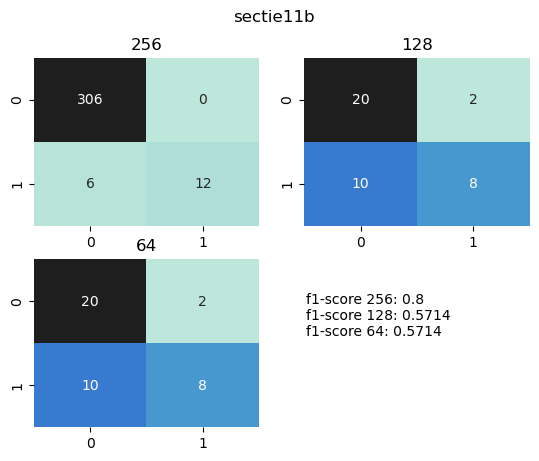

In [25]:
f1_256 = (2*array256[1][1])/(2*array256[1][1]+array256[0][1]+array256[1][0])
f1_128 = (2*array128[1][1])/(2*array128[1][1]+array128[0][1]+array128[1][0])
f1_64 = (2*array64[1][1])/(2*array64[1][1]+array64[0][1]+array64[1][0])

fig, ax = plt.subplots(nrows=2, ncols=2)
fig.suptitle(f'{name}')
# ax[0][0].imshow(filtered_data[33])
df256 = pd.DataFrame(array256, range(2), range(2))
sn.heatmap(df256, ax=ax[0][0], annot=True, center=array256[0][0], fmt='g', cbar=False)
ax[0][0].set_title('256')
df128 = pd.DataFrame(array128, range(2), range(2))
sn.heatmap(df128, ax=ax[0][1], annot=True, center=array128[0][0], fmt='g', cbar=False)
ax[0][1].set_title('128')
df64 = pd.DataFrame(array64, range(2), range(2))
sn.heatmap(df64, ax=ax[1][0], annot=True, center=array64[0][0], fmt='g', cbar=False)
ax[1][0].set_title('64')

ax[1][1].set_visible(False)

fig.text(0.55,0.3,f'f1-score 256: {round(f1_256,4)}\nf1-score 128: {round(f1_128,4)}\nf1-score 64: {round(f1_64,4)}')

plt.savefig(f'./documentation/pipeline_confusion_{name}.png')

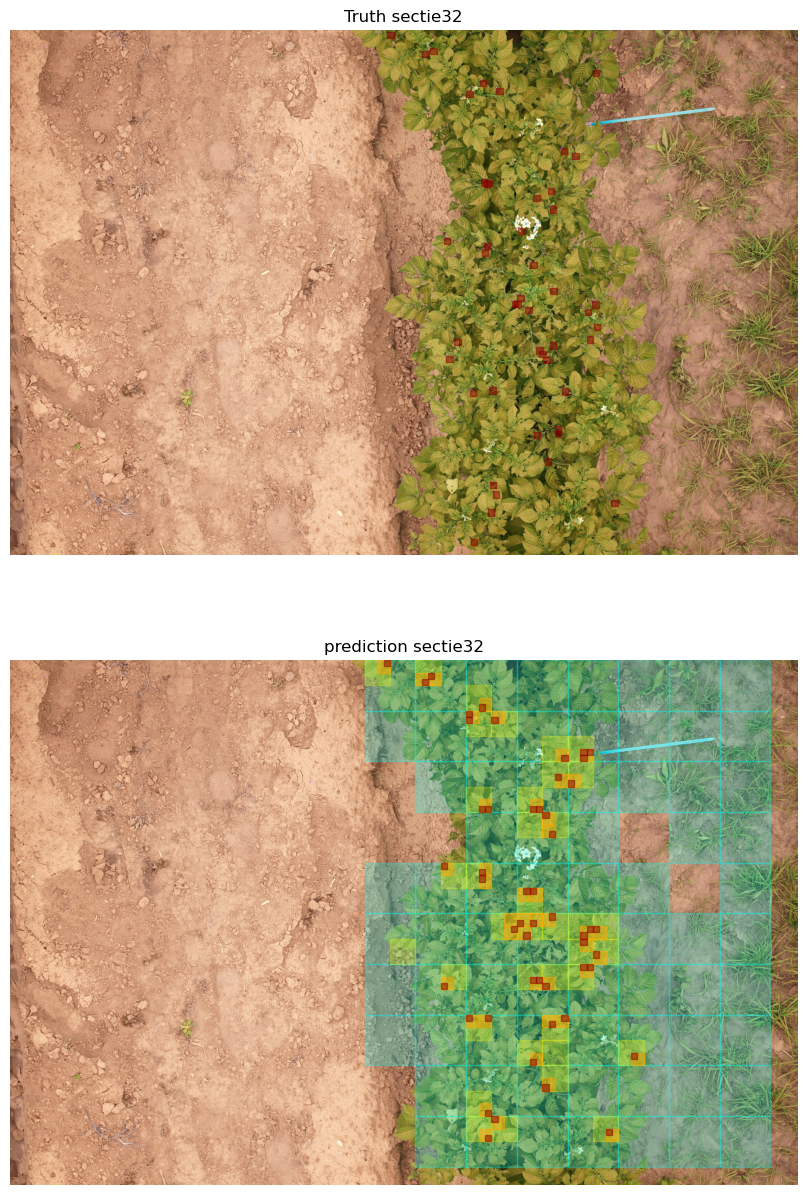

In [52]:
fig, ax = plt.subplots(2,1, figsize=(30,15))
ax[0].imshow(image)
ax[0].set_title(f'Truth {name}')

labels = open(f"./data/labels_full_txt/{name}.txt")

try:
    lines = [line.rstrip() for line in labels.readlines()]
except:
    lines = []

for line in lines:
    _, x_center, y_center, _, _ = [float(s) for s in line.split("\t")]
    rect = patches.Rectangle([round(x_center), round(y_center)], 64, 64, edgecolor = 'darkred', facecolor= 'darkred', alpha=0.5)
    ax[0].add_patch(rect)
ax[0].axis('off')

############################################################################

# fig, ax = plt.subplots()
ax[1].imshow(image)
ax[1].set_title(f'prediction {name}')
ax[1].axis('off')

size = 512
for x, y in filtered_label:
    rect = patches.Rectangle([x-size/2, y-size/2], size, size, edgecolor = 'aqua', facecolor= 'aqua', alpha=0.25)
    ax[1].add_patch(rect)
size = 256
for x, y in filtered_label256:
    rect = patches.Rectangle([x-size/2, y-size/2], size, size, edgecolor = 'yellow', facecolor= 'yellow', alpha=0.25)
    ax[1].add_patch(rect)
size = 128
for x, y in filtered_label128:
    rect = patches.Rectangle([x-size/2, y-size/2], size, size, edgecolor = 'orange', facecolor= 'orange', alpha=0.5)
    ax[1].add_patch(rect)
size = 64
for x, y in filtered_label64:
    rect = patches.Rectangle([x-size/2, y-size/2], size, size, edgecolor = 'darkred', facecolor= 'darkred', alpha=0.5)
    ax[1].add_patch(rect)
